CIS 360 - Spring 2026 - Assignment #2

Three practical applications of Face Detection:

1. Access Control - replace keys and cards with facial scans to allow access to restricted areas.
2. Vehicle Safety - AI systems detect driver drowsiness or distraction, triggering alarms.
3. Image Management - photo libraries can automatically group images by the person appearing in them.

RetinaFace is the face detection model built on the general object detection model of RetinaNet. The code below uses RetinaFace to identify faces in the image.


Number of faces detected:  11


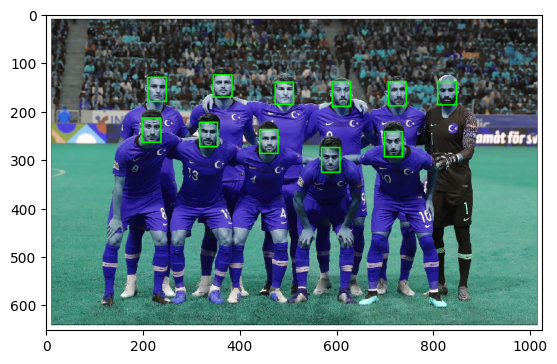

In [1]:
from retinaface import RetinaFace
import matplotlib.pyplot as plt
import cv2

IMG_PATH = 'sportsteam.png'
img = cv2.imread(IMG_PATH)
if img is not None:
  faces = RetinaFace.detect_faces(IMG_PATH)
  print('Number of faces detected: ', len(faces))
  for face in faces.items():
    x1, y1, x2, y2 = face[1]['facial_area'] 
    cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)  
  plt.imshow(img)
  plt.show()
else:
  print(f'Image {IMG_PATH} not found.')


It does not appear that any pre-processing of images is necessary to successfully use RetinaFace. Next, RetinaFace is used to identify faces in 3 video frames.

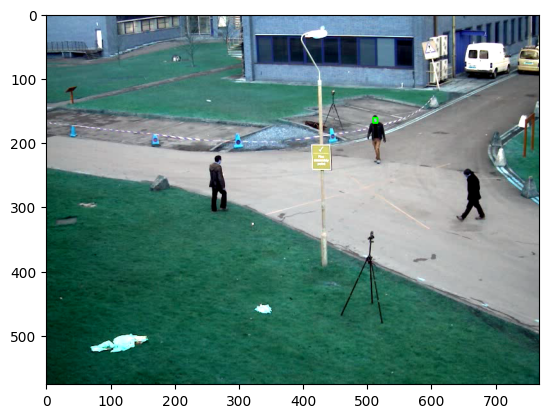

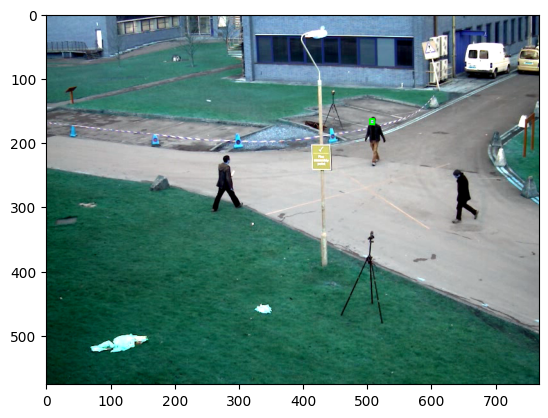

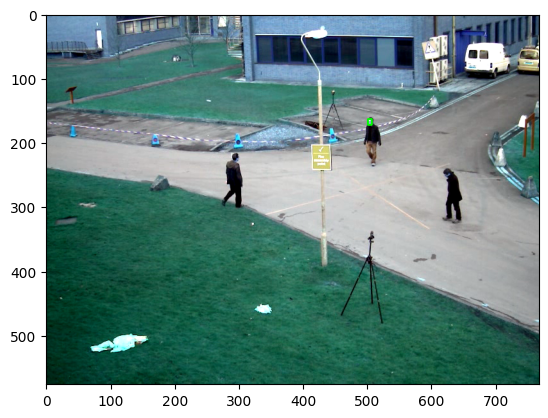

In [2]:
vid = cv2.VideoCapture('pedestrian_video.avi')
count = 1
while True:
    ret, frame = vid.read()
    if not ret:
        break
    faces = RetinaFace.detect_faces(frame)
    if len(faces) > 0:
        for face in faces.items():
            x1, y1, x2, y2 = face[1]['facial_area'] 
            cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 2) 
            count += 1 
        plt.imshow(frame)
        plt.show()
    if count > 3:
        break

The code below creates an API that accepts an image and return the facial area (x1, y1, x2, y2) of the faces in the image and returns those coordinates to the client.

In [29]:
from fastapi import FastAPI, File, UploadFile
import numpy as np

app = FastAPI(title="RetinaFace API")

@app.get("/")
def read_root():
    return {"message": "RetinaFace Face Detection API is running"}

@app.post("/detect-faces/")
async def detect_faces(file: UploadFile = File(...)):
    # Read image file
    contents = await file.read()
    np_arr = np.frombuffer(contents, np.uint8)
    img = cv2.imdecode(np_arr, cv2.IMREAD_COLOR)

    if img is None:
        return {"error": "Invalid image file"}

    faces = RetinaFace.detect_faces(img)

    results = []

    for face in faces.items():
        facial_area = face[1]['facial_area']
        result = []
        for coord in facial_area:
            result.append(int(coord)) # convert from numpy int64 to Python int
        results.append(result)

    return {
        "num_faces": len(faces),
        "faces": results
    }

In [30]:
import uvicorn

config = uvicorn.Config(app, host="127.0.0.1", port=8000)
server = uvicorn.Server(config)
await server.serve()

INFO:     Started server process [9156]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://127.0.0.1:8000 (Press CTRL+C to quit)


INFO:     127.0.0.1:54428 - "GET / HTTP/1.1" 200 OK
INFO:     127.0.0.1:54429 - "GET /favicon.ico HTTP/1.1" 404 Not Found
INFO:     127.0.0.1:54448 - "GET /docs HTTP/1.1" 200 OK
INFO:     127.0.0.1:54448 - "GET /openapi.json HTTP/1.1" 200 OK
INFO:     127.0.0.1:54455 - "POST /detect-faces/ HTTP/1.1" 200 OK


INFO:     Shutting down
INFO:     Waiting for application shutdown.
INFO:     Application shutdown complete.
INFO:     Finished server process [9156]
